# PCS26/84 — DEEP LEARNING-BASED FAKE NEWS DETECTION

## Notebook 02 — Traditional Machine-Learning Baselines, Leakage Ablations and the Frozen ML Model

| | |
|---|---|
| **Project code** | PCS26/84 |
| **Project title** | DEEP LEARNING-BASED FAKE NEWS DETECTION |
| **Position** | Notebook 2 of 5 (01 audit → **02 ML baselines** → 03 LSTM/BiLSTM → 04 transformer → 05 evaluation & explainability) |
| **Task / labels** | Binary text classification, **Fake = 0, Real = 1** |
| **Models** | TF-IDF + Logistic Regression, Multinomial Naive Bayes, Linear SVM — hyperparameters **fixed, not tuned** |



### Abstract
Classical linear models on sparse TF-IDF features are fast, transparent and surprisingly strong for news classification, so they are the reference every neural model must be compared with. This notebook (i) trains three baselines on the raw title + body input, (ii) tests, by **validation-only ablation**, how much of their accuracy depends on headline style and on publisher/format markers identified in Notebook 01, (iii) checks sensitivity to duplicates, near-duplicates and a subject shift, (iv) inspects the most influential n-grams and the validation errors, and (v) freezes one pipeline for the final comparison. All preprocessing is fitted on training rows only.

### Research questions
* **RQ1** How well do linear TF-IDF models separate Fake from Real *in-distribution*?
* **RQ2** How much of that performance survives when the headline and known publisher markers are removed?
* **RQ3** Do duplicates or near-duplicates inflate the validation scores?
* **RQ4** How robust are the models to a shift in news section (subject-held-out)?
* **RQ5** Which n-grams drive the decisions, and are they content words or format artefacts?

### Background and notation
**TF-IDF.** For term *t* in document *d* of a training corpus of *N* documents, with sublinear term frequency, `tfidf(t,d) = (1 + ln tf(t,d)) · ln((1+N)/(1+df(t))) + 1`, followed by L2 normalisation of each document vector. Unigrams and bigrams are used (`ngram_range=(1,2)`), with at most 100 000 features, `min_df=2`, `max_df=0.95`. *The vocabulary, document frequencies and the IDF weights are learned from training text only* — fitting them on validation or test text would leak information about those sets.

**Logistic Regression** models `P(Real | x) = σ(wᵀx + b)` and minimises the L2-regularised log-loss (`C = 5`, liblinear). **Linear SVM** minimises the L2-regularised hinge loss `½‖w‖² + C Σ max(0, 1 − yᵢ(wᵀxᵢ + b))` (`C = 1`); its signed margin is a score, **not** a calibrated probability. **Multinomial Naive Bayes** assumes features are conditionally independent given the class and uses smoothed (`α = 0.1`) class-conditional term weights — fast, but the independence assumption is strong for overlapping n-grams.

**Metrics.** With Real as the positive class: precision = TP/(TP+FP), recall = TP/(TP+FN), F1 = 2PR/(P+R). **Macro-F1** averages the Fake-class and Real-class F1 equally; **weighted-F1** weights them by class support. **ROC-AUC** is the probability that a random Real article receives a higher score than a random Fake article (threshold-free; requires continuous scores).

### Evaluation protocol and honest test-set history
* Models and input variants are **compared and selected on the validation set only**. The test set must not guide any choice because choosing the configuration that looks best on test makes the test score an optimistic estimate.
* **A Linear SVM trained on the raw title + body (variant V0) was evaluated once on the test set in the original version of this project (before Phase 1).** That result was therefore *seen*; this notebook does **not** describe the test set as untouched. It is kept in Appendix D for transparency, is not used for any selection, and describes a shortcut-inclusive input.
* The final-test cell in Part C evaluates the **frozen** Phase 1 model once, is off by default, and cannot run twice.
* No hyperparameter search was performed: the fixed values are those of the original notebook.

### Structure
| Part | Content |
|---|---|
| A | Original V0 baselines (raw title + body), validation only |
| B | Phase 1: integrity checks, marker rules, ablations V0–V5, sensitivity views, influential features, validation errors, selection, freezing |
| C | Final test evaluation of the frozen model (single use, off by default) |
| D | Legacy V0 test result (already observed) |

### How to run
Run **Notebook 01 first**, then **Restart & Run All** (≈ 20–40 min on a laptop CPU; TF-IDF refits dominate). Requires `src/fakenews_utils.py`, `scikit-learn pandas numpy matplotlib seaborn joblib scipy`.

## 1. Import Libraries and Configure Paths

In [1]:
from pathlib import Path
import datetime as dt
import json
import os
import sys
import warnings

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
)
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC

warnings.filterwarnings("default")


def find_project_root(marker="dataset"):
    here = Path.cwd().resolve()
    for candidate in [here, *here.parents]:
        if (candidate / marker).is_dir():
            return candidate
    raise FileNotFoundError(
        f"No '{marker}/' folder found above {here}. Open the notebook from the project root or notebooks/.")


PROJECT_ROOT = find_project_root()
DATA_PATH = PROJECT_ROOT / "dataset" / "combined_fake_news_clean.csv"
TABLES_DIR = PROJECT_ROOT / "results" / "tables"
FIGURES_DIR = PROJECT_ROOT / "results" / "figures"
MODELS_DIR = PROJECT_ROOT / "models" / "phase1"       # new folder: legacy model files are never touched
SRC_DIR = PROJECT_ROOT / "src"
for folder in (TABLES_DIR, FIGURES_DIR, MODELS_DIR):
    folder.mkdir(parents=True, exist_ok=True)

sys.path.insert(0, str(SRC_DIR))
if not (SRC_DIR / "fakenews_utils.py").exists():
    raise FileNotFoundError(f"{SRC_DIR / 'fakenews_utils.py'} not found. Copy the delivered src/ folder into the project root.")
import fakenews_utils as fu

RANDOM_STATE = 42
MIN_RULE_PREVALENCE = 0.01     # marker rule must occur in >=1% of one class ...
MIN_RULE_RATIO = 5.0           # ... and be >=5x more common in one class than the other (training data)

# Safety / control switches
OVERWRITE_PHASE1_MODELS = os.environ.get("FN_OVERWRITE_PHASE1", "0") == "1"
RUN_V5 = True                  # subject-held-out experiment (~12 extra TF-IDF fits)
RUN_FINAL_TEST = False         # <<< Part C. Leave False until the model is frozen and you are ready.
FINAL_DRYRUN = os.environ.get("FN_FINAL_DRYRUN", "0") == "1"   # developer smoke test: uses VALIDATION, writes DRYRUN files

assert DATA_PATH.exists(), f"Cleaned dataset not found: {DATA_PATH}"
print("Project root:", PROJECT_ROOT)
print("scikit-learn:", sklearn.__version__, "| pandas:", pd.__version__)

Project root: C:\Users\mi\Desktop\Fake-news detection
scikit-learn: 1.9.1 | pandas: 3.0.6


## 2. Load the Dataset, Restore Splits and Verify Integrity
The saved manifest is restored (never regenerated). Every integrity statement below is **computed**, replacing the previously hard-coded "Group-aware split verified: Yes".

In [2]:
df = pd.read_csv(DATA_PATH)
MANIFEST_PATH = TABLES_DIR / "data_split_manifest.csv"
assert MANIFEST_PATH.exists(), "Split manifest not found. Run Notebook 01 first (it never overwrites an existing manifest)."
manifest = pd.read_csv(MANIFEST_PATH)

train_idx = manifest.loc[manifest["partition"] == "train", "row_index"].astype(int).to_numpy()
val_idx = manifest.loc[manifest["partition"] == "validation", "row_index"].astype(int).to_numpy()
test_idx = manifest.loc[manifest["partition"] == "test", "row_index"].astype(int).to_numpy()

train_df = df.iloc[train_idx].copy()
val_df = df.iloc[val_idx].copy()
test_df = df.iloc[test_idx].copy()      # loaded for shape checks only; NOT scored before Part C

keys = fu.article_key(df["title"], df["text"])
g_train, g_val, g_test = (set(keys.iloc[i]) for i in (train_idx, val_idx, test_idx))

INTEGRITY = pd.DataFrame([
    ("Partitions cover every row exactly once",
     len(train_idx) + len(val_idx) + len(test_idx) == len(df)
     and set(manifest["row_index"]) == set(range(len(df))) and manifest["row_index"].is_unique),
    ("Row indices disjoint between partitions",
     set(train_idx).isdisjoint(val_idx) and set(train_idx).isdisjoint(test_idx) and set(val_idx).isdisjoint(test_idx)),
    ("No identical title+body group in train and validation", g_train.isdisjoint(g_val)),
    ("No identical title+body group in train and test", g_train.isdisjoint(g_test)),
    ("No identical title+body group in validation and test", g_val.isdisjoint(g_test)),
    ("Label values are exactly {0, 1}", set(df["label"].unique()) == {0, 1}),
    ("Both labels in every partition",
     all(set(p["label"].unique()) == {0, 1} for p in (train_df, val_df, test_df))),
], columns=["Check", "Passed"])
display(INTEGRITY)
assert INTEGRITY["Passed"].all(), "Integrity check failed - do not continue."

registry = fu.HashRegistry(TABLES_DIR / "phase1_hash_registry.json", PROJECT_ROOT)
print("Manifest hash:", registry.check(MANIFEST_PATH), "| clean CSV hash:", registry.check(DATA_PATH))
print(f"\nPartition sizes  train={len(train_df):,}  validation={len(val_df):,}  test={len(test_df):,}")
INTEGRITY.to_csv(TABLES_DIR / "p1_nb2_integrity_checks.csv", index=False)

,Check,Passed
0,Partitions cover every row exactly once,True
1,Row indices disjoint between partitions,True
2,No identical title+body group in train and val...,True
3,No identical title+body group in train and test,True
4,No identical title+body group in validation an...,True
5,"Label values are exactly {0, 1}",True
6,Both labels in every partition,True


Manifest hash: verified | clean CSV hash: verified

Partition sizes  train=30,796  validation=6,652  test=6,610


# Part A — Original V0 baselines 
The cells in Part A are the original baseline cells: input = raw title + body, TF-IDF fitted on all training rows, validation results only. They are kept as the reference for the new ablations. **Saved outputs of these cells come from your original run only if you did not re-execute the notebook; after a re-run they are fresh.**

##  Prepare Text Features and Target Labels

The title and article body will be combined to provide the text input for classification. The target variable is the binary news label, where 0 represents Fake News and 1 represents Real News.

The `subject` and `date` columns are excluded to reduce the risk of misleading shortcuts. Missing text values are handled safely before feature extraction.


In [3]:

# Prepare title + article text; exclude subject and date
def prepare_text(data):
    title = data["title"].fillna("").astype(str)
    article = data["text"].fillna("").astype(str)
    return (title.str.strip() + " " + article.str.strip()).str.strip()

X_train = prepare_text(train_df)
X_val = prepare_text(val_df)
X_test = prepare_text(test_df)

y_train = train_df["label"].astype(int)
y_val = val_df["label"].astype(int)
y_test = test_df["label"].astype(int)

# Verify that the data is ready
print("Training text:", len(X_train))
print("Validation text:", len(X_val))
print("Test text:", len(X_test))

print("\nTraining labels:")
print(y_train.value_counts().sort_index().rename(
    index={0: "Fake", 1: "Real"}
))

assert len(X_train) == len(y_train)
assert len(X_val) == len(y_val)
assert len(X_test) == len(y_test)

assert X_train.str.len().gt(0).all()
assert set(y_train.unique()) == {0, 1}
assert set(y_val.unique()) == {0, 1}
assert set(y_test.unique()) == {0, 1}

print("\nText features and labels prepared successfully!")

Training text: 30796
Validation text: 6652
Test text: 6610

Training labels:
label
Fake    15906
Real    14890
Name: count, dtype: int64

Text features and labels prepared successfully!


##  TF-IDF Feature Extraction

Term Frequency–Inverse Document Frequency (TF-IDF) converts news text into numerical features. It gives greater weight to terms that are informative within an article while reducing the influence of terms that occur frequently across many articles.

Unigrams and bigrams are included to capture individual words and two-word phrases. The vectorizer is fitted only on the training set; validation and test text are transformed using the fitted vectorizer.


In [4]:

# Create the TF-IDF vectorizer
tfidf = TfidfVectorizer(
    lowercase=True,
    strip_accents="unicode",
    ngram_range=(1, 2),
    max_features=100_000,
    min_df=2,
    max_df=0.95,
    sublinear_tf=True,
    dtype=np.float32
)

# Fit ONLY on training data
X_train_tfidf = tfidf.fit_transform(X_train)

# Transform validation and test data without refitting
X_val_tfidf = tfidf.transform(X_val)
X_test_tfidf = tfidf.transform(X_test)

print("TF-IDF feature extraction completed!")
print("Training matrix:", X_train_tfidf.shape)
print("Validation matrix:", X_val_tfidf.shape)
print("Test matrix:", X_test_tfidf.shape)
print("Vocabulary size:", len(tfidf.vocabulary_))

assert X_train_tfidf.shape[0] == len(y_train)
assert X_val_tfidf.shape[0] == len(y_val)
assert X_test_tfidf.shape[0] == len(y_test)

print("\nNo validation or test data was used to fit TF-IDF.")

TF-IDF feature extraction completed!
Training matrix: (30796, 100000)
Validation matrix: (6652, 100000)
Test matrix: (6610, 100000)
Vocabulary size: 100000

No validation or test data was used to fit TF-IDF.


##  Model 1 — Logistic Regression

Logistic Regression is a supervised machine-learning algorithm used for binary classification. In this project, it learns patterns in TF-IDF features to classify news articles as Fake (0) or Real (1).

The model will be trained on the training set and evaluated on the validation set using accuracy, precision, recall, and F1-score. The test set will not be used during model selection.


In [5]:

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Train Logistic Regression
lr_model = LogisticRegression(
    C=5.0,
    max_iter=1000,
    solver="liblinear",
    random_state=42
)

print("Training Logistic Regression...")
lr_model.fit(X_train_tfidf, y_train)

# Evaluate on validation data only
lr_val_pred = lr_model.predict(X_val_tfidf)

lr_results = {
    "Model": "Logistic Regression",
    "Accuracy": accuracy_score(y_val, lr_val_pred),
    "Precision": precision_score(y_val, lr_val_pred, zero_division=0),
    "Recall": recall_score(y_val, lr_val_pred, zero_division=0),
    "F1-Score": f1_score(y_val, lr_val_pred, zero_division=0)
}

print("\nLogistic Regression — Validation Results")
for metric, value in lr_results.items():
    if metric != "Model":
        print(f"{metric}: {value:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_val,
        lr_val_pred,
        labels=[0, 1],
        target_names=["Fake", "Real"],
        zero_division=0
    )
)

print("Logistic Regression training and validation completed!")

Training Logistic Regression...

Logistic Regression — Validation Results
Accuracy: 0.9943
Precision: 0.9924
Recall: 0.9955
F1-Score: 0.9939

Classification Report:
              precision    recall  f1-score   support

        Fake       1.00      0.99      0.99      3523
        Real       0.99      1.00      0.99      3129

    accuracy                           0.99      6652
   macro avg       0.99      0.99      0.99      6652
weighted avg       0.99      0.99      0.99      6652

Logistic Regression training and validation completed!


##  Model 2 — Multinomial Naive Bayes

Multinomial Naive Bayes is a probabilistic classification algorithm commonly used for text classification. It estimates class probabilities from word-related features and provides a fast baseline for comparison with Logistic Regression.

The model will be trained using the same training TF-IDF features and evaluated on the validation set. Test data are not used for fitting or for any model-selection decision.


In [6]:

from sklearn.naive_bayes import MultinomialNB

# Train Multinomial Naive Bayes
nb_model = MultinomialNB(alpha=0.1)

print("Training Multinomial Naive Bayes...")
nb_model.fit(X_train_tfidf, y_train)

# Evaluate on validation data
nb_val_pred = nb_model.predict(X_val_tfidf)

nb_results = {
    "Model": "Multinomial Naive Bayes",
    "Accuracy": accuracy_score(y_val, nb_val_pred),
    "Precision": precision_score(
        y_val, nb_val_pred, zero_division=0
    ),
    "Recall": recall_score(
        y_val, nb_val_pred, zero_division=0
    ),
    "F1-Score": f1_score(
        y_val, nb_val_pred, zero_division=0
    )
}

print("\nMultinomial Naive Bayes — Validation Results")
for metric, value in nb_results.items():
    if metric != "Model":
        print(f"{metric}: {value:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_val,
        nb_val_pred,
        labels=[0, 1],
        target_names=["Fake", "Real"],
        zero_division=0
    )
)

print("Naive Bayes training and validation completed!")

Training Multinomial Naive Bayes...

Multinomial Naive Bayes — Validation Results
Accuracy: 0.9614
Precision: 0.9547
Recall: 0.9636
F1-Score: 0.9591

Classification Report:
              precision    recall  f1-score   support

        Fake       0.97      0.96      0.96      3523
        Real       0.95      0.96      0.96      3129

    accuracy                           0.96      6652
   macro avg       0.96      0.96      0.96      6652
weighted avg       0.96      0.96      0.96      6652

Naive Bayes training and validation completed!


##  Model 3 — Linear Support Vector Machine (Linear SVM)

Linear Support Vector Machine is a supervised learning algorithm that identifies a decision boundary between classes. Linear SVM is often effective for high-dimensional text data, including TF-IDF representations.

The model will use the same training features and be evaluated on the validation set. Its performance will be compared with Logistic Regression and Multinomial Naive Bayes.


In [7]:

from sklearn.svm import LinearSVC

# Train Linear SVM
svm_model = LinearSVC(
    C=1.0,
    max_iter=3000,
    random_state=42
)

print("Training Linear SVM...")
svm_model.fit(X_train_tfidf, y_train)

# Evaluate on validation data
svm_val_pred = svm_model.predict(X_val_tfidf)

svm_results = {
    "Model": "Linear SVM",
    "Accuracy": accuracy_score(y_val, svm_val_pred),
    "Precision": precision_score(
        y_val, svm_val_pred, zero_division=0
    ),
    "Recall": recall_score(
        y_val, svm_val_pred, zero_division=0
    ),
    "F1-Score": f1_score(
        y_val, svm_val_pred, zero_division=0
    )
}

print("\nLinear SVM — Validation Results")
for metric, value in svm_results.items():
    if metric != "Model":
        print(f"{metric}: {value:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_val,
        svm_val_pred,
        labels=[0, 1],
        target_names=["Fake", "Real"],
        zero_division=0
    )
)

print("Linear SVM training and validation completed!")

Training Linear SVM...



Linear SVM — Validation Results
Accuracy: 0.9970
Precision: 0.9955
Recall: 0.9981
F1-Score: 0.9968

Classification Report:
              precision    recall  f1-score   support

        Fake       1.00      1.00      1.00      3523
        Real       1.00      1.00      1.00      3129

    accuracy                           1.00      6652
   macro avg       1.00      1.00      1.00      6652
weighted avg       1.00      1.00      1.00      6652

Linear SVM training and validation completed!


##  Model Comparison

This section compares Logistic Regression, Multinomial Naive Bayes, and Linear SVM using validation accuracy, precision, recall, and F1-score.

F1-score is included because it balances precision and recall. The model with the strongest validation performance will be considered for further evaluation, subject to leakage and generalization checks.

The test set will not be used to select the model.


In [8]:

# Collect validation results
results_df = pd.DataFrame([
    lr_results,
    nb_results,
    svm_results
])

results_df = results_df.sort_values(
    by="F1-Score",
    ascending=False
).reset_index(drop=True)

# Display percentage-based results
display(
    results_df.style.format({
        "Accuracy": "{:.2%}",
        "Precision": "{:.2%}",
        "Recall": "{:.2%}",
        "F1-Score": "{:.2%}"
    })
)

# Save the results
comparison_path = TABLES_DIR / "ml_baseline_comparison.csv"
results_df.to_csv(comparison_path, index=False)

print("\nComparison table saved to:", comparison_path)
print("Current leading model:", results_df.loc[0, "Model"])

,Model,Accuracy,Precision,Recall,F1-Score
0,Linear SVM,99.70%,99.55%,99.81%,99.68%
1,Logistic Regression,99.43%,99.24%,99.55%,99.39%
2,Multinomial Naive Bayes,96.14%,95.47%,96.36%,95.91%



Comparison table saved to: C:\Users\mi\Desktop\Fake-news detection\results\tables\ml_baseline_comparison.csv
Current leading model: Linear SVM


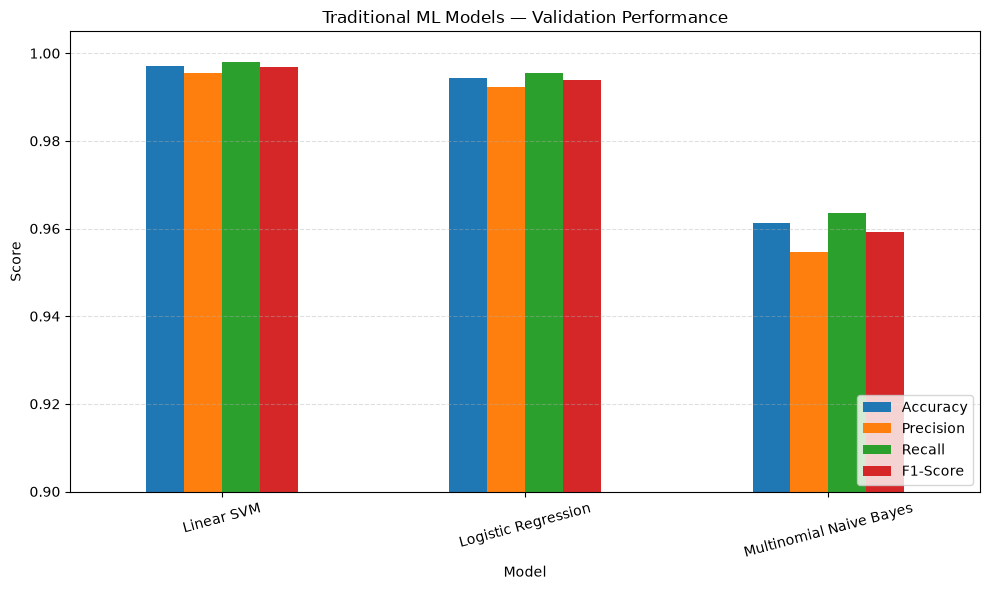

Comparison graph saved to: C:\Users\mi\Desktop\Fake-news detection\results\figures\15_ml_baseline_comparison.png


In [9]:

import matplotlib.pyplot as plt

metrics = ["Accuracy", "Precision", "Recall", "F1-Score"]

ax = (
    results_df.set_index("Model")[metrics]
    .plot(kind="bar", figsize=(10, 6), ylim=(0.90, 1.005))
)

ax.set_title("Traditional ML Models — Validation Performance")
ax.set_ylabel("Score")
ax.set_xlabel("Model")
ax.tick_params(axis="x", rotation=15)
ax.legend(loc="lower right")
ax.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()

graph_path = FIGURES_DIR / "15_ml_baseline_comparison.png"
plt.savefig(graph_path, dpi=300, bbox_inches="tight")
plt.show()

print("Comparison graph saved to:", graph_path)

##  Dataset Leakage and Generalization Checks
Very high classification scores can arise when a dataset contains repeated content or source-specific patterns. This cell re-checks whether identical normalised title–body pairs have conflicting labels and shows how strongly `subject` is associated with the label. Part B then tests directly — by ablation — how much of the performance depends on shortcuts.

In [10]:

# Check normalized title-text pairs in the cleaned dataset
audit = df.copy()

audit["normalized_pair"] = (
    audit["title"].fillna("").astype(str).str.strip().str.lower()
    + " || "
    + audit["text"].fillna("").astype(str).str.strip().str.lower()
)

pair_summary = audit.groupby("normalized_pair").agg(
    record_count=("label", "size"),
    unique_labels=("label", "nunique")
)

repeated_pairs = pair_summary[pair_summary["record_count"] > 1]
conflicting_pairs = pair_summary[pair_summary["unique_labels"] > 1]

print("Total cleaned records:", len(audit))
print("Unique normalized title-text pairs:", len(pair_summary))
print("Repeated pairs:", len(repeated_pairs))
print("Pairs with conflicting labels:", len(conflicting_pairs))

# Check whether subject is strongly associated with the label
if "subject" in audit.columns:
    subject_table = pd.crosstab(
        audit["subject"],
        audit["label"].map({0: "Fake", 1: "Real"})
    )
    display(subject_table)

    subject_table.to_csv(
        TABLES_DIR / "subject_label_leakage_check.csv"
    )

print("\nLeakage diagnostic completed.")

Total cleaned records: 44058
Unique normalized title-text pairs: 38656
Repeated pairs: 4943
Pairs with conflicting labels: 0


label,Fake,Real
subject,,
Government News,1498,0
Middle-east,778,0
News,9050,0
US_News,783,0
left-news,4309,0
politics,6430,0
politicsNews,0,11219
worldnews,0,9991



Leakage diagnostic completed.


##  Leakage Check — Findings and Limitations

The duplicate-content analysis identified 38,656 unique normalized title-text pairs among 44,058 cleaned records. A total of 4,943 pairs occurred more than once, and no repeated normalized pair had conflicting labels.

The subject-label distribution showed a strong association between subject categories and news labels. Several subject categories contained only Fake articles, while others contained only Real articles. Therefore, `subject` and `date` are excluded from the primary model's input features.

The group-aware split prevents identical normalized title-text pairs from crossing the training, validation, and test partitions. However, this does not eliminate every possible source of leakage or dataset bias. Models may still learn publisher-specific writing styles, recurring phrases, or other dataset-specific patterns.

The high validation scores should therefore be treated as in-distribution results on one dataset. Part B tests directly how much of them depends on shortcuts, and only an independent, multi-source dataset could show generalisation to unseen news sources.


In [11]:
used_input_columns = ["title", "text"]     # the only columns any model in this project receives

leakage_summary = pd.DataFrame({
    "Diagnostic": [
        "Cleaned records",
        "Unique normalized title-text pairs",
        "Repeated normalized pairs",
        "Pairs with conflicting labels",
        "Subject used as a model input",
        "Date used as a model input",
        "Group-aware split verified (computed from the manifest)",
    ],
    "Result": [
        len(audit),
        len(pair_summary),
        len(repeated_pairs),
        len(conflicting_pairs),
        "Yes" if "subject" in used_input_columns else "No",
        "Yes" if "date" in used_input_columns else "No",
        "Yes" if bool(INTEGRITY["Passed"].all()) else "NO - SEE INTEGRITY TABLE",
    ],
})
display(leakage_summary)
leakage_summary.to_csv(TABLES_DIR / "leakage_diagnostic_summary.csv", index=False)
print("Leakage diagnostic summary saved (values computed, not typed in).")

,Diagnostic,Result
0,Cleaned records,44058
1,Unique normalized title-text pairs,38656
2,Repeated normalized pairs,4943
3,Pairs with conflicting labels,0
4,Subject used as a model input,No
5,Date used as a model input,No
6,Group-aware split verified (computed from the ...,Yes


Leakage diagnostic summary saved (values computed, not typed in).


# Part B — Phase 1: Leakage ablations (validation only)

### Input variants
| ID | Input | Purpose |
|---|---|---|
| V0 | raw title + body | the original setting (shortcut-inclusive reference) |
| V1 | raw body only | removes the headline-style shortcut |
| V2 | raw title only | how far headline style alone goes |
| V3 | title + body, **publisher/format markers removed** | removes identified source markers |
| V4 | body only, publisher/format markers removed | closest to content-only |
| V5 | subject-held-out (V0 and V4 only; see B6) | tests robustness to a shift in news section |

### Pre-declared selection rule (written before any result is seen)
The model to freeze is the combination of variant ∈ {V3, V4} and family ∈ {Logistic Regression, Linear SVM, Naive Bayes} with the **highest validation macro-F1** (ties within 0.001 broken by ROC-AUC). V0–V2 are reported for comparison but cannot be selected, because V0–V2 retain the publisher/headline shortcuts and the project's claim is about content-based classification. All comparisons use the **same eligible examples** (see B2).

### Marker rules
Candidate patterns live in `src/fakenews_utils.py`. A pattern is **kept only if the training partition shows it is class-skewed** (≥ 1 % of one class and ≥ 5× more common there). Rules are applied in a fixed order and saved with the model, so training and prediction use identical preprocessing.

In [12]:
import gc

# Part A is finished. Release its large objects before the heavy Part B loops.
# The Part A result tables (results_df and the saved CSV files) are kept.
_released = []
for _name in ("X_train", "X_val", "X_test", "X_train_tfidf", "X_val_tfidf", "X_test_tfidf",
              "tfidf", "lr_model", "nb_model", "svm_model"):
    if _name in globals():
        del globals()[_name]
        _released.append(_name)
gc.collect()
print("Released Part A objects:", _released)

Released Part A objects: ['X_train', 'X_val', 'X_test', 'X_train_tfidf', 'X_val_tfidf', 'X_test_tfidf', 'tfidf', 'lr_model', 'nb_model', 'svm_model']


### B1. Discover which marker patterns actually occur (training data only)

In [13]:
y_train_arr = train_df["label"].to_numpy(int)
y_val_arr = val_df["label"].to_numpy(int)

rule_report = fu.compute_rule_report(
    train_df["title"], train_df["text"], y_train_arr, MIN_RULE_PREVALENCE, MIN_RULE_RATIO)
display(rule_report.sort_values("skew_ratio", ascending=False).round(4))

ACTIVE_RULES = rule_report.loc[rule_report["selected"], "rule"].tolist()
print("\nFrozen marker rules (selected on TRAINING data):", ACTIVE_RULES)
rule_report.to_csv(TABLES_DIR / "p1_marker_rule_report_train.csv", index=False)

print("\nRule definitions (regular expressions):")
for name in ACTIVE_RULES:
    print(f"  {name:20s} {fu.RULES_BY_NAME[name]['pattern']}")

,rule,description,prevalence_fake,prevalence_real,skew_ratio,selected
0,dateline_reuters,Leading '[CITY] (Reuters) -' dateline (seen in...,0.0001,0.9842,875.1146,True
4,featured_image,'Featured image (via ...)' caption phrase,0.3392,0.0000,340.1802,True
5,image_credit,'Photo/Image via|credit' caption phrase,0.2852,0.0000,286.2383,True
6,getty_images,'Getty Images' credit,0.1705,0.0000,171.5017,True
7,pic_twitter,Embedded tweet picture link,0.1503,0.0000,151.3206,True
1,reuters_token,Any remaining 'Reuters' token,0.0133,0.9984,69.7492,True
10,watch_label,'WATCH:' embed label,0.0594,0.0000,60.4115,True
3,century_wire,'21st Century Wire (says)' (seen in a Fake sam...,0.0541,0.0000,55.0676,True
8,url,URLs,0.1453,0.0020,48.5247,True
11,read_more_label,'READ MORE:' label,0.0320,0.0004,23.5221,True



Frozen marker rules (selected on TRAINING data): ['dateline_reuters', 'reuters_token', 'reporting_by_credit', 'century_wire', 'featured_image', 'image_credit', 'getty_images', 'pic_twitter', 'url', 'twitter_handle', 'watch_label', 'read_more_label']

Rule definitions (regular expressions):
  dateline_reuters     ^\s*(?:[A-Z][A-Za-z0-9.,'/&\- ]{0,60}?)?\(\s*Reuters\s*\)\s*[-\u2013\u2014:]*\s*
  reuters_token        \bReuters\b
  reporting_by_credit  \(\s*(?:Additional\s+)?(?:Reporting|Writing|Editing)\s+by[^)]{0,250}\)
  century_wire         \b21st\s+Century\s+Wire\b(?:\s+says)?
  featured_image       \bfeatured\s+image(?:\s+(?:via|credit|courtesy\s+of))?
  image_credit         \b(?:photo|image)\s+(?:via|credit|courtesy\s+of)\b
  getty_images         \bgetty\s+images?\b
  pic_twitter          \bpic\.twitter\.com/\S+
  url                  https?://\S+|\bwww\.\S+
  twitter_handle       (?<![\w.])@\w{1,15}\b
  watch_label          \bWATCH\b\s*[:\-\u2013\u2014]
  read_more_label      \bRE

### B2. Identical eligible examples across variants
Stripping markers can leave an article with no text (e.g. a body that was only a dateline). To compare variants fairly, a row is **eligible** only if its model input is non-empty under *every* variant. Rows dropped from training or validation are reported by class.

In [14]:
BUILDERS = {v: fu.make_builder(v, rule_names=ACTIVE_RULES).fit(train_df, y_train_arr) for v in fu.VARIANTS}

FULL_TEXT_CACHE = {}          # unfiltered model inputs, cached only for the (slower) marker-stripping variants


def full_texts(variant, part):
    key = (variant, part)
    if key in FULL_TEXT_CACHE:
        return FULL_TEXT_CACHE[key]
    frame = {"train": train_df, "validation": val_df}[part]
    texts = BUILDERS[variant].transform(frame)
    if fu.VARIANTS[variant]["strip_markers"]:
        FULL_TEXT_CACHE[key] = texts
    return texts


empty_by_variant = {}
rows = []
for v in fu.VARIANTS:
    for part, frame in (("train", train_df), ("validation", val_df)):
        texts = full_texts(v, part)
        empty = np.fromiter((len(t.split()) == 0 for t in texts), dtype=bool, count=len(texts))
        empty_by_variant[(v, part)] = empty
        lab = frame["label"].to_numpy()
        rows.append({"variant": v, "partition": part, "empty_inputs": int(empty.sum()),
                     "empty_Fake": int((empty & (lab == 0)).sum()), "empty_Real": int((empty & (lab == 1)).sum())})
empty_table = pd.DataFrame(rows)
display(empty_table)

ELIGIBLE = {
    part: ~np.any([empty_by_variant[(v, part)] for v in fu.VARIANTS], axis=0)
    for part in ("train", "validation")
}
elig_rows = []
for part, frame in (("train", train_df), ("validation", val_df)):
    lab = frame["label"].to_numpy()
    elig_rows.append({"partition": part, "rows": len(frame), "eligible": int(ELIGIBLE[part].sum()),
                      "dropped": int((~ELIGIBLE[part]).sum()),
                      "dropped_Fake": int((~ELIGIBLE[part] & (lab == 0)).sum()),
                      "dropped_Real": int((~ELIGIBLE[part] & (lab == 1)).sum())})
eligibility_table = pd.DataFrame(elig_rows)
print("\nEligibility used for ALL variants and models:")
display(eligibility_table)
eligibility_table.to_csv(TABLES_DIR / "p1_eligibility_by_partition.csv", index=False)

train_el_pos = np.flatnonzero(ELIGIBLE["train"])
val_el_pos = np.flatnonzero(ELIGIBLE["validation"])
y_tr = y_train_arr[train_el_pos]
y_va = y_val_arr[val_el_pos]
val_el_df = val_df.iloc[val_el_pos]


def eligible_texts(variant, part):
    texts = full_texts(variant, part)
    pos = train_el_pos if part == "train" else val_el_pos
    return [texts[i] for i in pos]

# Save which rows are eligible so Notebooks 03-05 use exactly the same examples.
eligible_rows = pd.concat([
    pd.DataFrame({"row_index": train_df.index, "partition": "train", "eligible": ELIGIBLE["train"]}),
    pd.DataFrame({"row_index": val_df.index, "partition": "validation", "eligible": ELIGIBLE["validation"]}),
], ignore_index=True)
eligible_rows.to_csv(TABLES_DIR / "p1_eligible_rows.csv", index=False)

,variant,partition,empty_inputs,empty_Fake,empty_Real
0,V0,train,0,0,0
1,V0,validation,0,0,0
2,V1,train,0,0,0
3,V1,validation,0,0,0
4,V2,train,0,0,0
5,V2,validation,0,0,0
6,V3,train,8,8,0
7,V3,validation,0,0,0
8,V4,train,61,61,0
9,V4,validation,9,9,0



Eligibility used for ALL variants and models:


,partition,rows,eligible,dropped,dropped_Fake,dropped_Real
0,train,30796,30735,61,61,0
1,validation,6652,6643,9,9,0


### B3. Ablation experiments V0–V4 (validation only)
For every variant the builder (frozen rules) and TF-IDF are fitted on eligible **training** rows; Logistic Regression, Naive Bayes and Linear SVM (fixed hyperparameters) are trained on the same matrix and scored on the eligible **validation** rows. Reported: accuracy, per-class precision/recall, macro-F1 and ROC-AUC (Real = positive class).

In [15]:
import time
MODEL_SPECS = {
    "Logistic Regression": lambda: LogisticRegression(C=5.0, max_iter=1000, solver="liblinear", random_state=RANDOM_STATE),
    "Multinomial NB": lambda: MultinomialNB(alpha=0.1),
    "Linear SVM": lambda: LinearSVC(C=1.0, max_iter=3000, random_state=RANDOM_STATE),
}

FITTED = {}        # (variant, model) -> end-to-end Pipeline (builder -> tfidf -> classifier)
VAL_OUT = {}       # (variant, model) -> (val predictions, val scores) on eligible validation rows
ablation_rows = []

for v, spec in fu.VARIANTS.items():
    tfidf_v = fu.make_tfidf()
    t0 = time.perf_counter()
    X_tr = tfidf_v.fit_transform(eligible_texts(v, "train"))     # fitted on eligible TRAIN rows only
    tfidf_fit_s = time.perf_counter() - t0
    t0 = time.perf_counter()
    X_va = tfidf_v.transform(eligible_texts(v, "validation"))
    tfidf_transform_s = time.perf_counter() - t0
    for model_name, make in MODEL_SPECS.items():
        t0 = time.perf_counter()
        clf = make().fit(X_tr, y_tr)
        clf_fit_s = time.perf_counter() - t0
        t0 = time.perf_counter()
        pred = clf.predict(X_va)
        predict_s = time.perf_counter() - t0
        score = fu.positive_class_score(clf, X_va)
        ablation_rows.append({"variant": v, "input": spec["description"], "model": model_name,
                              **fu.evaluate_binary(y_va, pred, score),
                              "tfidf_fit_s": tfidf_fit_s, "tfidf_transform_val_s": tfidf_transform_s,
                              "clf_fit_s": clf_fit_s, "clf_predict_val_s": predict_s})
        FITTED[(v, model_name)] = fu.assemble_pipeline(BUILDERS[v], tfidf_v, clf)
        VAL_OUT[(v, model_name)] = (pred, score)
    print(f"{v} done  (features: {len(tfidf_v.vocabulary_):,})")
    del X_tr, X_va

ablation_df = pd.DataFrame(ablation_rows)
ablation_df.to_csv(TABLES_DIR / "p1_ablation_validation_metrics.csv", index=False)

show_cols = ["variant", "input", "model", "n", "accuracy", "precision_fake", "recall_fake",
             "precision_real", "recall_real", "macro_f1", "roc_auc"]
display(ablation_df[show_cols].round(4))

# Validation predictions/scores of every (variant, model) on the eligible rows (used by Notebook 05).
pred_tbl = pd.DataFrame({"row_index": val_el_df.index, "label": y_va})
for (_v, _m), (_p, _sc) in VAL_OUT.items():
    pred_tbl[f"{_v}|{_m}|pred"] = _p
    pred_tbl[f"{_v}|{_m}|score"] = _sc
pred_tbl.to_csv(TABLES_DIR / "p1_val_predictions_all_variants.csv", index=False)

V0 done  (features: 100,000)
V1 done  (features: 100,000)
V2 done  (features: 71,884)
V3 done  (features: 100,000)
V4 done  (features: 100,000)


,variant,input,model,n,accuracy,precision_fake,recall_fake,precision_real,recall_real,macro_f1,roc_auc
0,V0,Raw title + body,Logistic Regression,6643,0.9943,0.9960,0.9932,0.9924,0.9955,0.9943,0.9997
1,V0,Raw title + body,Multinomial NB,6643,0.9612,0.9670,0.9593,0.9547,0.9632,0.9610,0.9920
2,V0,Raw title + body,Linear SVM,6643,0.9970,0.9983,0.9960,0.9955,0.9981,0.9970,0.9999
3,V1,Body only (raw),Logistic Regression,6643,0.9928,0.9951,0.9912,0.9901,0.9946,0.9928,0.9996
4,V1,Body only (raw),Multinomial NB,6643,0.9591,0.9669,0.9553,0.9505,0.9632,0.9589,0.9912
5,V1,Body only (raw),Linear SVM,6643,0.9953,0.9980,0.9932,0.9924,0.9978,0.9953,0.9999
6,V2,Title only (raw),Logistic Regression,6643,0.9591,0.9696,0.9525,0.9477,0.9664,0.9590,0.9915
7,V2,Title only (raw),Multinomial NB,6643,0.9472,0.9559,0.9437,0.9376,0.9511,0.9470,0.9896
8,V2,Title only (raw),Linear SVM,6643,0.9585,0.9704,0.9505,0.9456,0.9674,0.9584,0.9922
9,V3,"Title + body, publisher markers removed",Logistic Regression,6643,0.9892,0.9917,0.9878,0.9863,0.9907,0.9891,0.9994


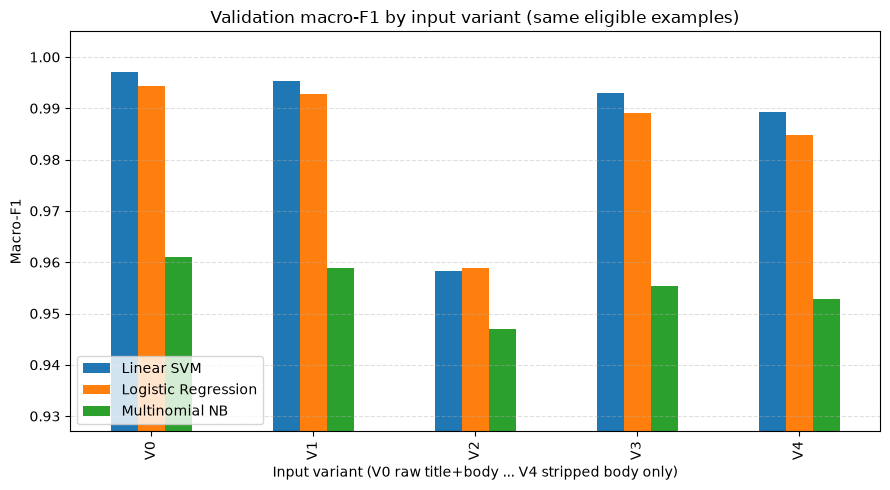

Saved: C:\Users\mi\Desktop\Fake-news detection\results\figures\17_p1_ablation_macro_f1.png

Best validation macro-F1 per variant:
  V0 (Raw title + body): 0.9970  [Linear SVM]
  V1 (Body only (raw)): 0.9953  [Linear SVM]
  V2 (Title only (raw)): 0.9590  [Logistic Regression]
  V3 (Title + body, publisher markers removed): 0.9929  [Linear SVM]
  V4 (Body only, publisher markers removed): 0.9893  [Linear SVM]

Change in best macro-F1 from V0 (raw title+body) to V4 (stripped body only): -0.0077


In [16]:
pivot = ablation_df.pivot(index="variant", columns="model", values="macro_f1")
ax = pivot.plot(kind="bar", figsize=(9, 5))
ax.set_title("Validation macro-F1 by input variant (same eligible examples)")
ax.set_ylabel("Macro-F1")
ax.set_xlabel("Input variant (V0 raw title+body ... V4 stripped body only)")
lo = max(0.0, float(np.nanmin(pivot.to_numpy())) - 0.02)
ax.set_ylim(lo, 1.005)
ax.grid(axis="y", linestyle="--", alpha=0.4)
ax.legend(loc="lower left")
plt.tight_layout()
fig_path = FIGURES_DIR / "17_p1_ablation_macro_f1.png"
plt.savefig(fig_path, dpi=300, bbox_inches="tight")
plt.show()
print("Saved:", fig_path)

best_per_variant = (ablation_df.sort_values(["macro_f1", "roc_auc"], ascending=False)
                    .groupby("variant").head(1).sort_values("variant"))
print("\nBest validation macro-F1 per variant:")
for _, r in best_per_variant.iterrows():
    print(f"  {r.variant} ({r.input}): {r.macro_f1:.4f}  [{r.model}]")
v0 = float(best_per_variant.loc[best_per_variant.variant == "V0", "macro_f1"].iloc[0])
v4 = float(best_per_variant.loc[best_per_variant.variant == "V4", "macro_f1"].iloc[0])
print(f"\nChange in best macro-F1 from V0 (raw title+body) to V4 (stripped body only): {v4 - v0:+.4f}")

In [17]:
# Macro AND weighted averages from the stored validation predictions (no refitting).
from sklearn.metrics import precision_recall_fscore_support
rows = []
for (v, model_name), (pred, score) in VAL_OUT.items():
    p_m, r_m, f_m, _ = precision_recall_fscore_support(y_va, pred, average="macro", zero_division=0)
    p_w, r_w, f_w, _ = precision_recall_fscore_support(y_va, pred, average="weighted", zero_division=0)
    rows.append({"variant": v, "model": model_name, "macro_precision": p_m, "macro_recall": r_m, "macro_f1": f_m,
                 "weighted_precision": p_w, "weighted_recall": r_w, "weighted_f1": f_w,
                 "support_Fake": int((y_va == 0).sum()), "support_Real": int((y_va == 1).sum())})
macro_weighted = pd.DataFrame(rows)
macro_weighted.to_csv(TABLES_DIR / "p1_ablation_macro_weighted.csv", index=False)
display(macro_weighted.round(4))

# Training / inference cost measured inside the ablation loop (single run, this machine).
cost_cols = ["variant", "model", "tfidf_fit_s", "tfidf_transform_val_s", "clf_fit_s", "clf_predict_val_s"]
cost = ablation_df[cost_cols].copy()
display(cost.round(2))
cost.to_csv(TABLES_DIR / "p1_ablation_timing.csv", index=False)

,variant,model,macro_precision,macro_recall,macro_f1,weighted_precision,weighted_recall,weighted_f1,support_Fake,support_Real
0,V0,Logistic Regression,0.9942,0.9943,0.9943,0.9943,0.9943,0.9943,3514,3129
1,V0,Multinomial NB,0.9609,0.9613,0.9610,0.9612,0.9612,0.9612,3514,3129
2,V0,Linear SVM,0.9969,0.9970,0.9970,0.9970,0.9970,0.9970,3514,3129
3,V1,Logistic Regression,0.9926,0.9929,0.9928,0.9928,0.9928,0.9928,3514,3129
4,V1,Multinomial NB,0.9587,0.9593,0.9589,0.9592,0.9591,0.9591,3514,3129
5,V1,Linear SVM,0.9952,0.9955,0.9953,0.9953,0.9953,0.9953,3514,3129
6,V2,Logistic Regression,0.9586,0.9595,0.9590,0.9593,0.9591,0.9591,3514,3129
7,V2,Multinomial NB,0.9468,0.9474,0.9470,0.9473,0.9472,0.9472,3514,3129
8,V2,Linear SVM,0.9580,0.9589,0.9584,0.9587,0.9585,0.9585,3514,3129
9,V3,Logistic Regression,0.9890,0.9892,0.9891,0.9892,0.9892,0.9892,3514,3129


,variant,model,tfidf_fit_s,tfidf_transform_val_s,clf_fit_s,clf_predict_val_s
0,V0,Logistic Regression,37.53,5.51,3.18,0.01
1,V0,Multinomial NB,37.53,5.51,0.09,0.02
2,V0,Linear SVM,37.53,5.51,0.92,0.01
3,V1,Logistic Regression,33.16,5.06,3.33,0.01
4,V1,Multinomial NB,33.16,5.06,0.12,0.02
5,V1,Linear SVM,33.16,5.06,1.01,0.02
6,V2,Logistic Regression,1.51,0.23,0.32,0.00
7,V2,Multinomial NB,1.51,0.23,0.02,0.00
8,V2,Linear SVM,1.51,0.23,0.19,0.00
9,V3,Logistic Regression,36.82,5.44,3.23,0.01


### Findings — ablation (validation set, eligible rows, fixed hyperparameters)
*Numbers below come from the verification run on the uploaded data; the tables above are authoritative if your run differs.*

| Input variant | Linear SVM macro-F1 | Logistic Regression | Naive Bayes |
|---|---|---|---|
| V0 raw title + body | 0.9970 | 0.9943 | 0.9614 |
| V1 body only | 0.9953 | 0.9928 | 0.9586 |
| V2 **title only** | 0.9584 | 0.9590 | 0.9470 |
| V3 title + body, markers removed | 0.9929 | 0.9891 | 0.9555 |
| V4 body only, markers removed | 0.9891 | 0.9848 | 0.9532 |

1. **RQ1.** In-distribution, the linear models are extremely accurate: Linear SVM reaches 0.9970 macro-F1 (ROC-AUC 0.9999) on raw input; Logistic Regression is close; Naive Bayes is clearly weaker (0.9614). Model ranking (SVM ≳ LR > NB) is the same in every variant.
2. **RQ2.** Removing the headline costs 0.0017; additionally removing the identified markers costs a further 0.0062. The body-only, marker-stripped SVM still scores 0.9891. **So the Reuters dateline and page-furniture markers are *not* the sole source of the high accuracy.** A plausible but *untested* explanation is that many other source-specific style differences remain (vocabulary, reporting conventions, topics); the influential-feature tables below show that format tokens such as "via", "video", "read more" and "factbox" still carry weight after stripping. V3/V4 mean "*known* markers removed", not "shortcut-free".
3. **Headline style alone** (V2) already gives 0.9584 macro-F1 — far above chance — confirming the headline-length separation found in Notebook 01.
4. Differences between SVM and LR are small (≈ 0.003–0.005 macro-F1); with a few dozen errors per model they should not be over-interpreted. Naive Bayes' lower score is consistent with its independence assumption, but that was not isolated experimentally.
5. **Cost.** Fitting TF-IDF dominates training time; the classifiers themselves fit quickly and prediction is fast (see the timing table).

### B5. Sensitivity views (validation only)
The same models scored on (a) all eligible validation rows, (b) a **de-duplicated** view (one row per identical title+body group), and (c) a **near-duplicate-free** view (no training article with TF-IDF cosine ≥ 0.90; from Notebook 01). If a model's score changes a lot between views, repeated or near-repeated articles were inflating it.

In [18]:
GROUP_INFO_PATH = TABLES_DIR / "split_group_info.csv"
val_keys = fu.article_key(val_el_df["title"], val_el_df["text"])
view_dedup = ~val_keys.duplicated().to_numpy()

views = {"all eligible": np.ones(len(val_el_df), dtype=bool), "de-duplicated": view_dedup}
if GROUP_INFO_PATH.exists():
    gi = pd.read_csv(GROUP_INFO_PATH).set_index("row_index")
    near = gi.loc[val_el_df.index, "near_dup_max_sim"].to_numpy()
    views["near-duplicate-free (<0.90)"] = near < 0.90
else:
    print("split_group_info.csv not found (run Notebook 01) - near-duplicate view skipped.")

rows = []
for (v, model_name), (pred, score) in VAL_OUT.items():
    if model_name == "Multinomial NB":
        continue
    for view_name, mask in views.items():
        m = fu.evaluate_binary(y_va[mask], pred[mask], score[mask])
        rows.append({"variant": v, "model": model_name, "view": view_name, "n": m["n"],
                     "accuracy": m["accuracy"], "macro_f1": m["macro_f1"], "roc_auc": m["roc_auc"]})
sensitivity_df = pd.DataFrame(rows)
sensitivity_df.to_csv(TABLES_DIR / "p1_sensitivity_views_validation.csv", index=False)
display(sensitivity_df.pivot_table(index=["variant", "model"], columns="view", values="macro_f1").round(4))
print("Rows per view:", {k: int(m.sum()) for k, m in views.items()})

view                         all eligible  de-duplicated  \
variant model                                              
V0      Linear SVM                 0.9970         0.9969   
        Logistic Regression        0.9943         0.9939   
V1      Linear SVM                 0.9953         0.9955   
        Logistic Regression        0.9928         0.9927   
V2      Linear SVM                 0.9584         0.9577   
        Logistic Regression        0.9590         0.9579   
V3      Linear SVM                 0.9929         0.9931   
        Logistic Regression        0.9891         0.9891   
V4      Linear SVM                 0.9893         0.9899   
        Logistic Regression        0.9848         0.9856   

view                         near-duplicate-free (<0.90)  
variant model                                             
V0      Linear SVM                                0.9969  
        Logistic Regression                       0.9941  
V1      Linear SVM                                0.9952  
        Logistic Regression                       0.9926  
V2      Linear SVM                                0.9574  
        Logistic Regression                       0.9581  
V3      Linear SVM                                0.9927  
        Logistic Regression                       0.9889  
V4      Linear SVM                                0.9890  
        Logistic Regression                       0.9844

Rows per view: {'all eligible': 6643, 'de-duplicated': 5792, 'near-duplicate-free (<0.90)': 6505}


### Findings — sensitivity views (RQ3)
Scores on the de-duplicated and the near-duplicate-free views differ from the full validation score by at most about 0.001 macro-F1 for every variant. **Duplicates and near-duplicates therefore do not explain the high validation scores** in this split. They remain a limitation (a small share of articles has a close training twin) but not the main explanation.

### B6. V5 — subject-held-out experiment (validation only)
**Feasibility:** `subject` is perfectly nested in the label (every subject is only Fake or only Real). A held-out fold is therefore built by holding out **one Real subject and one Fake subject together**, training on the *training partition* rows of all other subjects, and scoring the *validation partition* rows of the held-out subjects. Both classes appear in training and in the held-out set, so the fold is valid.

**What it does and does not show.** Both Real subjects come from the same publisher, so this tests robustness to a shift in *news section/topic*, **not** to a shift in publisher. Marker rules are the frozen ones from B1 (selected on the whole training partition), a minor deviation noted here. Only V0 and V4 with Logistic Regression and Linear SVM are run.

In [19]:
V5_MIN_HELDOUT_PER_CLASS = 100
subj_train_all = train_df["subject"].to_numpy()
subj_val_all = val_df["subject"].to_numpy()

real_subjects = sorted(train_df.loc[train_df["label"] == 1, "subject"].unique())
fake_subject_counts = train_df.loc[train_df["label"] == 0, "subject"].value_counts()
fake_subjects = list(fake_subject_counts.index[:3])      # three largest Fake subjects
print("Real subjects:", real_subjects, "| Fake subjects used for hold-out:", fake_subjects)

v5_rows = []
if not RUN_V5:
    print("RUN_V5 is False - skipped.")
elif len(real_subjects) < 2 or len(fake_subject_counts) < 2:
    print("V5 is NOT feasible: fewer than two subjects in a class, so no fold can hold out a subject "
          "and still leave that class in training.")
else:
    for r_subj in real_subjects:
        for f_subj in fake_subjects:
            held = [r_subj, f_subj]
            tr_mask = ELIGIBLE["train"] & ~np.isin(subj_train_all, held)
            va_mask = ELIGIBLE["validation"] & np.isin(subj_val_all, held)
            y_tr5, y_va5 = y_train_arr[tr_mask], y_val_arr[va_mask]
            n_va = {c: int((y_va5 == c).sum()) for c in (0, 1)}
            if len(set(y_tr5)) < 2 or min(n_va.values()) < V5_MIN_HELDOUT_PER_CLASS:
                print(f"fold held-out {held}: SKIPPED (not enough examples of both classes)")
                continue
            for v in ("V0", "V4"):
                tr_texts_all, va_texts_all = full_texts(v, "train"), full_texts(v, "validation")
                tr_texts = [tr_texts_all[i] for i in np.flatnonzero(tr_mask)]
                va_texts = [va_texts_all[i] for i in np.flatnonzero(va_mask)]
                tf = fu.make_tfidf()
                Xt, Xv = tf.fit_transform(tr_texts), tf.transform(va_texts)
                for model_name in ("Logistic Regression", "Linear SVM"):
                    clf = MODEL_SPECS[model_name]().fit(Xt, y_tr5)
                    pred, score = clf.predict(Xv), fu.positive_class_score(clf, Xv)
                    v5_rows.append({"held_out_real": r_subj, "held_out_fake": f_subj, "variant": v,
                                    "model": model_name, "train_n": int(tr_mask.sum()),
                                    "heldout_Fake": n_va[0], "heldout_Real": n_va[1],
                                    **fu.evaluate_binary(y_va5, pred, score)})
                del Xt, Xv
            print(f"fold held-out {held}: done")

v5_df = pd.DataFrame(v5_rows)
if len(v5_df):
    v5_df.to_csv(TABLES_DIR / "p1_v5_subject_heldout.csv", index=False)
    display(v5_df[["held_out_real", "held_out_fake", "variant", "model", "heldout_Fake", "heldout_Real",
                   "accuracy", "recall_fake", "recall_real", "macro_f1", "roc_auc"]].round(4))
    print("\nMean over folds:")
    display(v5_df.groupby(["variant", "model"])[["accuracy", "macro_f1", "roc_auc"]].mean().round(4))

Real subjects: ['politicsNews', 'worldnews'] | Fake subjects used for hold-out: ['News', 'politics', 'left-news']
fold held-out ['politicsNews', 'News']: done
fold held-out ['politicsNews', 'politics']: done
fold held-out ['politicsNews', 'left-news']: done
fold held-out ['worldnews', 'News']: done
fold held-out ['worldnews', 'politics']: done
fold held-out ['worldnews', 'left-news']: done


,held_out_real,held_out_fake,variant,model,heldout_Fake,heldout_Real,accuracy,recall_fake,recall_real,macro_f1,roc_auc
0,politicsNews,News,V0,Logistic Regression,1360,1626,0.7425,0.9993,0.5277,0.7350,0.9907
1,politicsNews,News,V0,Linear SVM,1360,1626,0.7937,0.9993,0.6218,0.7909,0.9944
2,politicsNews,News,V4,Logistic Regression,1360,1626,0.6899,0.9978,0.4323,0.6743,0.9808
3,politicsNews,News,V4,Linear SVM,1360,1626,0.7251,0.9971,0.4975,0.7155,0.9841
4,politicsNews,politics,V0,Logistic Regression,1015,1626,0.7179,0.9901,0.5480,0.7174,0.9728
5,politicsNews,politics,V0,Linear SVM,1015,1626,0.7724,0.9911,0.6359,0.7724,0.9866
6,politicsNews,politics,V4,Logistic Regression,1015,1626,0.6501,0.9882,0.4391,0.6459,0.9426
7,politicsNews,politics,V4,Linear SVM,1015,1626,0.6838,0.9872,0.4945,0.6820,0.9605
8,politicsNews,left-news,V0,Logistic Regression,672,1626,0.6480,0.9911,0.5062,0.6463,0.9716
9,politicsNews,left-news,V0,Linear SVM,672,1626,0.7219,0.9970,0.6082,0.7165,0.9858



Mean over folds:


accuracy  macro_f1  roc_auc
variant model                                           
V0      Linear SVM             0.8731    0.8712   0.9940
        Logistic Regression    0.8340    0.8314   0.9878
V4      Linear SVM             0.8165    0.8134   0.9819
        Logistic Regression    0.7889    0.7841   0.9739

### Findings — subject-held-out experiment V5 (RQ4)
*Scope reminder: both Real subjects come from the same publisher, so this tests a shift in news **section/topic**, not in publisher.*

Averaged over the six folds, the Linear SVM falls from ≈ 0.87 macro-F1 on raw input (V0) to ≈ 0.81 on marker-stripped body text (V4), while ROC-AUC stays high (≈ 0.99 → ≈ 0.98). The pattern is highly asymmetric: when **`worldnews`** is held out, accuracy is ≈ 0.98; when **`politicsNews`** is held out, accuracy drops to ≈ 0.72–0.79 because **Real recall falls to ≈ 0.61–0.64** while Fake recall stays ≈ 0.99. The high AUC shows that the *ranking* of articles is still good, but the **decision threshold learned on the training sections no longer fits**: politics-section Real news is pushed toward "Fake" when it was not seen in training. This is evidence that the classifier partly encodes news *section/style*, and that headline accuracy numbers will not carry over to a different source mix.

### B7. Model selection (validation only, pre-declared rule)

In [20]:
candidates = ablation_df[ablation_df["variant"].isin(["V3", "V4"])].copy()
top = candidates["macro_f1"].max()
near_top = candidates[candidates["macro_f1"] >= top - 0.001]
chosen = near_top.sort_values("roc_auc", ascending=False).iloc[0]

SELECTED_VARIANT, SELECTED_MODEL = chosen["variant"], chosen["model"]
print("Candidates considered (V3/V4 x model families):")
display(candidates[["variant", "model", "macro_f1", "roc_auc", "accuracy"]].sort_values("macro_f1", ascending=False).round(4))
print(f"\nSELECTED (validation macro-F1 {chosen['macro_f1']:.4f}, ROC-AUC {chosen['roc_auc']:.4f}): "
      f"variant {SELECTED_VARIANT} ({fu.VARIANTS[SELECTED_VARIANT]['description']}) + {SELECTED_MODEL}")
print("Selection used validation data only; no test data has been scored in Part B.")

Candidates considered (V3/V4 x model families):


,variant,model,macro_f1,roc_auc,accuracy
11,V3,Linear SVM,0.9929,0.9997,0.9929
14,V4,Linear SVM,0.9893,0.9995,0.9893
9,V3,Logistic Regression,0.9891,0.9994,0.9892
12,V4,Logistic Regression,0.9848,0.9991,0.9848
10,V3,Multinomial NB,0.9555,0.9895,0.9556
13,V4,Multinomial NB,0.9529,0.9885,0.9530



SELECTED (validation macro-F1 0.9929, ROC-AUC 0.9997): variant V3 (Title + body, publisher markers removed) + Linear SVM
Selection used validation data only; no test data has been scored in Part B.


### B8. Most influential n-grams (Logistic Regression and Linear SVM)
Positive weights push toward **Real (1)**, negative toward **Fake (0)**. Read the V0 columns for shortcut tokens, then read the **selected variant** to check what remains after marker stripping. If non-content tokens (site names, caption words, credits) still dominate the selected variant, add a rule to `src/fakenews_utils.py` and re-run from B1 — this loop uses training/validation data only and must be finished **before** Part C.

In [21]:
feature_tables = {}
for v in sorted({"V0", SELECTED_VARIANT}):
    for model_name in ("Logistic Regression", "Linear SVM"):
        pipe = FITTED[(v, model_name)]
        tbl = fu.top_linear_features(pipe.named_steps["tfidf"], pipe.named_steps["clf"], n=30)
        feature_tables[(v, model_name)] = tbl
        tbl.to_csv(TABLES_DIR / f"p1_top_features_{v}_{model_name.replace(' ', '_')}.csv", index=False)

for (v, model_name), tbl in feature_tables.items():
    print(f"\n=== {v} - {model_name} (top 30 per direction) ===")
    display(tbl.round(3))


=== V0 - Logistic Regression (top 30 per direction) ===


,rank,toward_Fake,weight_Fake,toward_Real,weight_Real
0,1,via,-14.753,reuters,31.503
1,2,video,-12.301,said,15.096
2,3,read more,-8.604,washington reuters,13.073
3,4,read,-7.254,said on,10.666
4,5,obama,-6.956,reuters the,8.140
5,6,just,-6.900,on wednesday,7.562
6,7,president trump,-6.882,on tuesday,7.542
7,8,this,-6.771,washington,7.156
8,9,image,-6.628,president donald,6.928
9,10,watch,-6.578,on,6.848



=== V0 - Linear SVM (top 30 per direction) ===


,rank,toward_Fake,weight_Fake,toward_Real,weight_Real
0,1,via,-5.402,reuters,11.936
1,2,video,-3.559,washington reuters,4.392
2,3,read more,-3.376,said,4.195
3,4,read,-2.548,said on,2.858
4,5,president trump,-2.353,reuters the,2.629
5,6,featured image,-2.068,on tuesday,2.346
6,7,image,-2.061,on wednesday,2.238
7,8,the us,-2.048,reuters president,2.091
8,9,obama,-2.012,president donald,2.074
9,10,gop,-2.009,on thursday,2.050



=== V3 - Logistic Regression (top 30 per direction) ===


,rank,toward_Fake,weight_Fake,toward_Real,weight_Real
0,1,video,-14.903,said,18.443
1,2,via,-13.939,said on,12.975
2,3,read more,-8.781,president donald,9.447
3,4,just,-8.252,on wednesday,9.100
4,5,this,-8.234,on tuesday,9.017
5,6,gop,-7.986,on,8.539
6,7,president trump,-7.830,on thursday,8.317
7,8,us,-7.662,on friday,7.756
8,9,the us,-7.406,said in,7.697
9,10,obama,-7.237,on monday,6.921



=== V3 - Linear SVM (top 30 per direction) ===


,rank,toward_Fake,weight_Fake,toward_Real,weight_Real
0,1,via,-5.350,said,5.622
1,2,video,-4.799,said on,3.734
2,3,read more,-3.644,president donald,3.299
3,4,president trump,-2.776,on tuesday,2.948
4,5,gop,-2.734,on wednesday,2.920
5,6,the us,-2.619,on,2.746
6,7,read,-2.605,on thursday,2.708
7,8,this,-2.493,on friday,2.451
8,9,just,-2.492,said in,2.318
9,10,us,-2.373,on monday,2.186


### Findings — influential n-grams (RQ5)
Positive weights push toward Real, negative toward Fake. On **raw input (V0)** the single strongest Real feature is `reuters` (and `washington reuters`), while Fake features include page furniture (`via`, `video`, `read more`, `featured image`, `watch`). After marker stripping (V3) the dominant features are still largely **style and format tokens** — `via`, `video`, `read more`, `watch`, `breaking`, `factbox`, weekday phrases ("on tuesday") — rather than topical content. This is an *association in the training data*, not a causal explanation: such tokens are cheap proxies for a source's house style. They are the natural next candidates for additional cleaning rules; any extension must be decided on training/validation data only and **before** the final test cell is run.

### B9. Validation error analysis (selected model)
Errors on the **validation** set only. These are for understanding, never for tuning against the test set.

In [22]:
pred_sel, score_sel = VAL_OUT[(SELECTED_VARIANT, SELECTED_MODEL)]
err = val_el_df.assign(pred=pred_sel, score=score_sel)
err["body_words"] = err["text"].astype(str).str.split().str.len()
wrong = err[err["pred"] != err["label"]].copy()
wrong["error_type"] = np.where(wrong["label"] == 0, "Fake predicted Real (false positive)", "Real predicted Fake (false negative)")

print(f"Validation errors: {len(wrong)} of {len(err)} eligible rows")
display(wrong["error_type"].value_counts().to_frame("count"))

print("\nErrors by subject:")
by_subject = err.groupby("subject").apply(lambda g: pd.Series({"rows": len(g), "errors": int((g["pred"] != g["label"]).sum())}), include_groups=False)
by_subject["error_rate_pct"] = (by_subject["errors"] / by_subject["rows"] * 100).round(2)
display(by_subject)

err["length_bucket"] = pd.cut(err["body_words"], [0, 50, 150, 400, 1000, 10**6], labels=["<=50", "51-150", "151-400", "401-1000", ">1000"])
print("\nErrors by body length (words):")
by_len = err.groupby("length_bucket", observed=True).apply(lambda g: pd.Series({"rows": len(g), "errors": int((g["pred"] != g["label"]).sum())}), include_groups=False)
by_len["error_rate_pct"] = (by_len["errors"] / by_len["rows"] * 100).round(2)
display(by_len)

show = wrong.assign(abs_score=wrong["score"].abs()).sort_values("abs_score", ascending=False).head(20)
display(show.assign(text_start=show["text"].astype(str).str.slice(0, 220))[["title", "text_start", "subject", "label", "pred", "score"]])
wrong.drop(columns=["text"]).to_csv(TABLES_DIR / "p1_validation_errors_selected_model.csv", index=True)

Validation errors: 47 of 6643 eligible rows


,count
error_type,
Fake predicted Real (false positive),30
Real predicted Fake (false negative),17



Errors by subject:


,rows,errors,error_rate_pct
subject,,,
Government News,243,7,2.88
Middle-east,112,0,0.00
News,1360,4,0.29
US_News,112,0,0.00
left-news,672,5,0.74
politics,1015,14,1.38
politicsNews,1626,13,0.80
worldnews,1503,4,0.27



Errors by body length (words):


,rows,errors,error_rate_pct
length_bucket,,,
<=50,248,1,0.40
51-150,1006,2,0.20
151-400,2591,17,0.66
401-1000,2586,21,0.81
>1000,212,6,2.83


,title,text_start,subject,label,pred,score
15870,BREAKING: NORTH KOREA Detains American Student...,Apparently it takes just one American student ...,politics,0,1,0.747657
16006,BREAKING: NORTH KOREA Detains American Student...,Apparently it takes just one American student ...,Government News,0,1,0.747657
33617,BREAKING: Activist Appeals Court Rules Against...,A federal appeals court ruled that the U.S. wi...,politics,0,1,0.721181
28965,Highlights of Reuters interview with Trump,WASHINGTON (Reuters) - Here are highlights of ...,politicsNews,1,0,-0.559564
13200,EXPERT CLAIMS N. KOREA’S SECOND MISSILE Test D...,When asked if a pre-emptive military strike is...,politics,0,1,0.419028
37118,Special Report: Why an emblematic American cit...,"MUNCIE, Indiana (Reuters) - One night a month...",politicsNews,1,0,-0.357389
43660,"UNITED AIRLINES GROUNDED, WALL STREET JOURNAL ...","So the NYSE, Wall Street Journal and United Ai...",Government News,0,1,0.337695
2503,"Emmy winners throw jabs at Trump, Spicer wheel...",LOS ANGELES (Reuters) - The Emmy awards show w...,politicsNews,1,0,-0.330435
21297,RACE BAITING LIBERALS WILL HATE TRUMP’S CHOICE...,"Ken Blackwell, the Ohio Republican selected by...",politics,0,1,0.301719
38490,Supreme Court To Hear Major Wisconsin Gerryma...,In a case that could have far-reaching consequ...,News,0,1,0.246733


### Findings — validation errors of the selected model
The selected pipeline makes **47 errors on 6,643 eligible validation rows (30 Fake predicted Real, 17 Real predicted Fake)**. Errors are spread across subjects (politics 14, politicsNews 13, Government News 7, left-news 5, worldnews 4, News 4), so no single section dominates. Errors are **not** concentrated in very short bodies: their median length is 440 words (overall median ≈ 365) and only one has fewer than 50 words. Thirteen of the 47 error rows share a headline with another error row — the same article listed under two subjects and therefore counted twice — so the number of *distinct* mistaken articles is smaller. Among the most confident errors are Fake articles with sensational "BREAKING:"-style headlines predicted Real, and long Real interview or special-report pieces predicted Fake, i.e. articles whose style departs from the typical pattern of their class. Error analysis is for understanding only; it is not used to tune against the test set.

### B10. Freeze and save the selected model
The fitted end-to-end pipeline (marker rules → TF-IDF → classifier), the label mapping and a configuration record are saved with `joblib`/JSON into `models/phase1/` (a *new* folder; legacy model files are never touched). Existing Phase 1 files are **not overwritten**: if they exist, the new selection is compared with them and the notebook stops if they disagree (set `FN_OVERWRITE_PHASE1=1` only if you intend to replace them).

In [23]:
selected_pipeline = FITTED[(SELECTED_VARIANT, SELECTED_MODEL)]
bundle_path = MODELS_DIR / "ml_selected_pipeline.joblib"
config_path = MODELS_DIR / "ml_selected_config.json"
label_path = MODELS_DIR / "label_mapping.json"

# End-to-end consistency: predicting from the RAW validation DataFrame must reproduce the stored predictions.
e2e_pred = selected_pipeline.predict(val_el_df[["title", "text"]])
assert (e2e_pred == VAL_OUT[(SELECTED_VARIANT, SELECTED_MODEL)][0]).all(), "Pipeline predictions differ from experiment predictions."
print("End-to-end pipeline reproduces the experiment predictions on validation.")

signature = {"variant": SELECTED_VARIANT, "model": SELECTED_MODEL, "active_rules": ACTIVE_RULES}
val_metrics = fu.evaluate_binary(y_va, *VAL_OUT[(SELECTED_VARIANT, SELECTED_MODEL)])

if bundle_path.exists() and config_path.exists() and not OVERWRITE_PHASE1_MODELS:
    existing = json.loads(config_path.read_text())
    if existing.get("signature") != signature:
        raise RuntimeError(
            "A frozen Phase 1 model already exists with a DIFFERENT selection:\n"
            f"  existing: {existing.get('signature')}\n  new:      {signature}\n"
            "Existing artifacts are protected. Delete them deliberately, or set FN_OVERWRITE_PHASE1=1, if you really want to replace them.")
    bundle = fu.load_bundle(bundle_path)
    print("Existing frozen model matches the current selection - kept unchanged (not overwritten).")
else:
    bundle = {
        "pipeline": selected_pipeline,
        "label_map": fu.LABEL_MAP,
        "variant": SELECTED_VARIANT,
        "model": SELECTED_MODEL,
        "active_rules": ACTIVE_RULES,
        "created_utc": dt.datetime.now(dt.timezone.utc).isoformat(timespec="seconds"),
        "sklearn_version": sklearn.__version__,
        "disclaimer": fu.DISCLAIMER,
    }
    joblib.dump(bundle, bundle_path)
    config = {
        "signature": signature,
        "input_description": fu.VARIANTS[SELECTED_VARIANT]["description"],
        "label_mapping": fu.LABEL_MAP,
        "marker_rule_patterns": {r: fu.RULES_BY_NAME[r]["pattern"] for r in ACTIVE_RULES},
        "rule_selection": {"min_prevalence": MIN_RULE_PREVALENCE, "min_ratio": MIN_RULE_RATIO, "fitted_on": "training partition"},
        "tfidf_params": {k: str(v) for k, v in fu.TFIDF_KWARGS.items()},
        "classifier_params": {k: str(v) for k, v in selected_pipeline.named_steps["clf"].get_params().items()},
        "hyperparameter_search_performed": False,
        "training_rows": int(len(train_el_pos)),
        "validation_rows": int(len(val_el_pos)),
        "validation_metrics": val_metrics,
        "selection_rule": "highest validation macro-F1 among V3/V4 x {LR, SVM, NB}; ties within 0.001 by ROC-AUC",
        "created_utc": bundle["created_utc"],
        "sklearn_version": sklearn.__version__,
        "bundle_sha256": fu.sha256_file(bundle_path),
        "test_set_used_for_selection": False,
        "disclaimer": fu.DISCLAIMER,
    }
    config_path.write_text(json.dumps(config, indent=2))
    label_path.write_text(json.dumps(fu.LABEL_MAP, indent=2))
    print("Saved:", bundle_path.name, config_path.name, label_path.name)

print("Frozen-model hash:", registry.check(bundle_path))

# Reproducible prediction function demo (validation rows + a hand-written text; no test data).
for i in range(2):
    row = val_el_df.iloc[i]
    out = fu.predict_article(row["title"], row["text"], bundle)
    print(f"\nValidation row {val_el_df.index[i]}: true={fu.ID_TO_LABEL[int(row['label'])]}  ->  {out['label']}  "
          f"(margin/prob: {out.get('decision_margin', out.get('probability_real'))})")
print("\nShort hand-written text:", fu.predict_article("Example", "A short sentence.", bundle))

End-to-end pipeline reproduces the experiment predictions on validation.
Existing frozen model matches the current selection - kept unchanged (not overwritten).
Frozen-model hash: verified

Validation row 3: true=Fake  ->  Fake  (margin/prob: -0.9222667270424176)

Validation row 6: true=Fake  ->  Fake  (margin/prob: -1.4208042574131747)

Short hand-written text: {'label': 'Real', 'label_id': 1, 'n_words_used': 4, 'disclaimer': "This model predicts whether an article resembles the 'Fake' or 'Real' class of its training dataset. It does not verify factual claims.", 'decision_margin': 0.18201647005377874, 'margin_note': 'Signed margin (positive -> Real). Not a calibrated probability.', 'warning': 'Only 4 words after preprocessing; the model was trained on full articles, so this prediction is unreliable.'}


**Interpretation (freeze).** The end-to-end check passed: predicting from raw `title`/`text` reproduces the stored experiment predictions exactly, so training-time and inference-time preprocessing are identical. The saved bundle contains the marker rules, TF-IDF vocabulary and classifier together with the label map; `predict_article` returns a label plus a decision margin (SVM) or probability, and warns on very short input. A score or probability describes similarity to the training classes, **not factual correctness**.

In [24]:
# Save the fitted Logistic Regression pipeline in the same bundle format as the SVM artifact.
# NOTHING IS REFITTED: the pipeline already fitted in B3 is reused, and its predictions are checked after reloading.
lr_key = (SELECTED_VARIANT, "Logistic Regression")
lr_pipeline = FITTED[lr_key]
lr_val_pred = VAL_OUT[lr_key][0]
lr_bundle_path = MODELS_DIR / "ml_logistic_regression_pipeline.joblib"


def check_lr_bundle(path):
    """Reload `path`; compare its metadata and its validation predictions with this notebook run."""
    b = fu.load_bundle(path)
    meta_ok = (b.get("variant") == SELECTED_VARIANT and b.get("model") == "Logistic Regression"
               and b.get("active_rules") == ACTIVE_RULES and b.get("label_map") == fu.LABEL_MAP)
    preds_ok = bool((b["pipeline"].predict(val_el_df[["title", "text"]]) == lr_val_pred).all())
    return b, meta_ok, preds_ok


if lr_bundle_path.exists() and not OVERWRITE_PHASE1_MODELS:
    # Protected: an existing artifact is never overwritten. It is only verified.
    lr_bundle, meta_ok, preds_ok = check_lr_bundle(lr_bundle_path)
    if not (meta_ok and preds_ok):
        raise RuntimeError(
            f"{lr_bundle_path.name} already exists but does NOT match this notebook run "
            f"(metadata ok: {meta_ok}, predictions ok: {preds_ok}). It was NOT overwritten. "
            "Rename or move the old file, or set FN_OVERWRITE_PHASE1=1 only if you really want to replace it.")
    print("Existing Logistic Regression artifact matches this run - kept unchanged (not overwritten).")
else:
    lr_bundle = {
        "pipeline": lr_pipeline,
        "label_map": fu.LABEL_MAP,
        "variant": SELECTED_VARIANT,
        "model": "Logistic Regression",
        "active_rules": ACTIVE_RULES,
        "created_utc": dt.datetime.now(dt.timezone.utc).isoformat(timespec="seconds"),
        "sklearn_version": sklearn.__version__,
        "disclaimer": fu.DISCLAIMER,
    }
    joblib.dump(lr_bundle, lr_bundle_path)
    print("Saved:", lr_bundle_path.relative_to(PROJECT_ROOT))
    lr_bundle, meta_ok, preds_ok = check_lr_bundle(lr_bundle_path)

assert meta_ok, "Reloaded Logistic Regression bundle has different metadata than this run."
assert preds_ok, "Reloaded Logistic Regression pipeline does not reproduce this notebook's validation predictions."
print(f"Verification passed: reloaded bundle reproduces all {len(lr_val_pred):,} validation predictions "
      f"(variant {SELECTED_VARIANT}, {len(ACTIVE_RULES)} marker rules, scikit-learn {lr_bundle['sklearn_version']}).")
print("Hash registry:", registry.check(lr_bundle_path, strict=False))

demo = fu.predict_article(val_el_df.iloc[0]["title"], val_el_df.iloc[0]["text"], lr_bundle)
assert "probability_real" in demo, "Logistic Regression should return a probability."
print("Example from the reloaded bundle:", {k: v for k, v in demo.items() if k != "disclaimer"})

Existing Logistic Regression artifact matches this run - kept unchanged (not overwritten).
Verification passed: reloaded bundle reproduces all 6,643 validation predictions (variant V3, 12 marker rules, scikit-learn 1.9.1).
Hash registry: recorded
Example from the reloaded bundle: {'label': 'Fake', 'label_id': 0, 'n_words_used': 193, 'probability_real': 0.05490253626922341}


# Part C — FINAL TEST EVALUATION OF THE FROZEN MODEL (single use)

**Read before running.** Everything above has been decided on training/validation data. This cell evaluates the saved, hash-checked model on the held-out **test set exactly once**. Do **not** run it while you are still changing marker rules, variants or models.

* Off by default (`RUN_FINAL_TEST = False` in the setup cell). Set it to `True` only when you are finished with Part B.
* It refuses to run twice: once `results/tables/p1_ml_final_test_results.json` exists, later runs only display the stored result.
* It does not influence any earlier choice. The old raw-input (V0) test result (Appendix D) is a separate, earlier observation.
* Reported: accuracy, per-class precision/recall, macro-F1, ROC-AUC, group-bootstrap 95 % CIs, a de-duplicated view, a near-duplicate-free view, confusion matrix and classification report. Predictions are saved so Notebook 03 can run a paired McNemar test against the deep-learning model.

In [25]:
PART = "validation" if FINAL_DRYRUN else "test"
TAG = "DRYRUN_" if FINAL_DRYRUN else ""
FINAL_JSON = TABLES_DIR / f"p1_ml_final_{TAG}test_results.json" if not FINAL_DRYRUN else TABLES_DIR / "p1_ml_final_DRYRUN_results.json"
FINAL_PRED = TABLES_DIR / (f"p1_ml_final_{TAG}test_predictions.csv" if not FINAL_DRYRUN else "p1_ml_final_DRYRUN_predictions.csv")

if FINAL_JSON.exists() and not FINAL_DRYRUN:
    print("A final test result already exists - NOT re-evaluating (single-use rule). Stored result:\n")
    print(json.dumps(json.loads(FINAL_JSON.read_text()), indent=2)[:3000])
elif not (RUN_FINAL_TEST or FINAL_DRYRUN):
    print("RUN_FINAL_TEST is False - final test evaluation NOT run. Freeze the model in B10 first.")
else:
    if FINAL_DRYRUN:
        print("*** DEVELOPER DRY RUN: using the VALIDATION partition to exercise this code path. ***")
    # 1) the model must be exactly the frozen one
    cfg = json.loads(config_path.read_text())
    assert fu.sha256_file(bundle_path) == cfg["bundle_sha256"], "Frozen model file changed after freezing."
    frozen = fu.load_bundle(bundle_path)
    pipe = frozen["pipeline"]

    frame = test_df if PART == "test" else val_df
    texts = pipe.named_steps["text"].transform(frame)
    keep_rows = np.fromiter((len(t.split()) > 0 for t in texts), dtype=bool, count=len(texts))
    frame_el = frame.loc[keep_rows]
    y_true = frame_el["label"].to_numpy(int)
    pred = pipe.predict(frame_el[["title", "text"]])
    clf = pipe.named_steps["clf"]
    score = pipe.decision_function(frame_el[["title", "text"]]) if hasattr(clf, "decision_function") \
        else pipe.predict_proba(frame_el[["title", "text"]])[:, 1]

    k = fu.article_key(frame_el["title"], frame_el["text"])
    dedup = ~k.duplicated().to_numpy()
    views = {"all eligible": np.ones(len(frame_el), dtype=bool), "de-duplicated": dedup}
    if GROUP_INFO_PATH.exists():
        gi = pd.read_csv(GROUP_INFO_PATH).set_index("row_index")
        views["near-duplicate-free (<0.90)"] = gi.loc[frame_el.index, "near_dup_max_sim"].to_numpy() < 0.90

    results = {"partition": PART, "frozen_model": cfg["signature"], "rows_scored": int(len(frame_el)),
               "rows_without_usable_text": int((~keep_rows).sum()), "views": {}}
    for view_name, mask in views.items():
        results["views"][view_name] = fu.evaluate_binary(y_true[mask], pred[mask], score[mask])

    acc_ci = fu.bootstrap_ci(y_true, pred, lambda a, b: float((a == b).mean()), groups=k.to_numpy(), n_boot=1000, seed=RANDOM_STATE)
    f1_ci = fu.bootstrap_ci(y_true, pred, lambda a, b: float(f1_score(a, b, average="macro")), groups=k.to_numpy(), n_boot=1000, seed=RANDOM_STATE)
    results["accuracy_95ci_group_bootstrap"] = acc_ci
    results["macro_f1_95ci_group_bootstrap"] = f1_ci

    cm = confusion_matrix(y_true, pred, labels=[0, 1])
    results["confusion_matrix_[[TN_fake_ok, fake_as_real],[real_as_fake, TP_real_ok]]"] = cm.tolist()
    FINAL_JSON.write_text(json.dumps(results, indent=2))
    pd.DataFrame({"row_index": frame_el.index, "label": y_true, "pred": pred, "score": score}).to_csv(FINAL_PRED, index=False)

    print(classification_report(y_true, pred, labels=[0, 1], target_names=["Fake", "Real"], digits=4))
    print(f"Accuracy {results['views']['all eligible']['accuracy']:.4f}  95% CI {acc_ci[0]:.4f}-{acc_ci[1]:.4f} | "
          f"macro-F1 {results['views']['all eligible']['macro_f1']:.4f}  95% CI {f1_ci[0]:.4f}-{f1_ci[1]:.4f} | "
          f"ROC-AUC {results['views']['all eligible']['roc_auc']:.4f}")
    display(pd.DataFrame(results["views"]).T.round(4))
    ConfusionMatrixDisplay(cm, display_labels=["Fake", "Real"]).plot(cmap="Blues", values_format="d")
    plt.title(f"Frozen ML model - {PART} confusion matrix")
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / f"18_p1_ml_final_{PART}_confusion_matrix{'_DRYRUN' if FINAL_DRYRUN else ''}.png", dpi=300, bbox_inches="tight")
    plt.show()
    print("Saved:", FINAL_JSON.name, "and", FINAL_PRED.name)

RUN_FINAL_TEST is False - final test evaluation NOT run. Freeze the model in B10 first.


# Summary, limitations and threats to validity

**Completed and verified in this notebook.** Computed split-integrity checks; marker-rule discovery on training data; V0–V4 ablations on identical eligible rows; macro/weighted metrics and timing; sensitivity to duplicates; a subject-held-out experiment (section shift only); influential n-grams; validation error analysis; selection by a pre-declared validation-only rule (**V3 + Linear SVM**, validation macro-F1 0.9929); a frozen, hash-checked, reloadable pipeline.

**What the evidence supports.** Linear TF-IDF models separate the two classes almost perfectly *within this dataset*; the headline alone is highly informative; removing known publisher markers lowers but does not remove the performance; duplicates are not the explanation; performance degrades noticeably under a section shift.

**What it does not support.** That the models detect falsehood, that residual signal is "content" rather than source style, or that scores transfer to other publishers or periods.

**Threats to validity.** Source confounding; one dataset and period; marker rules are heuristics chosen from training prevalence; single run (no cross-validation or multiple seeds); fixed, untuned hyperparameters; eligibility excludes a few dozen Fake rows whose bodies became empty after stripping; the legacy V0 test result was observed before the Phase 1 design.

**Next notebook.** Notebook 03 trains LSTM/BiLSTM on the *same* frozen input, so ML and DL are compared on identical examples.

# Appendix D — Legacy V0 test result (observed before Phase 1)
The original notebook evaluated the raw-input (V0) Linear SVM once on the test set (reported then: accuracy 99.59 %, precision 99.34 %, recall 99.81 %, F1 99.58 %; confusion matrix 3398 / 21 / 6 / 3185). That number was **seen before** the Phase 1 variants were designed; it is kept for transparency, it is **not** used for any selection, and it describes a shortcut-inclusive setting. The replay below is off by default so the test set is not inspected repeatedly; the original result files (`svm_test_results.csv`, `svm_test_confusion_matrix.csv`) are not modified by this notebook.

### Interpretation of the legacy V0 test result
*Observed in the original run, before Phase 1; not used for any selection and **not** a claim that the test set is untouched.*

The raw-input Linear SVM reached 99.59 % accuracy, 99.34 % precision, 99.81 % recall and 99.58 % F1 (Real = positive class) on the test partition — close to its validation scores. Similar validation and test scores show that the two partitions behave alike; they do **not** show reliability on other sources, because both partitions share the same publisher confound, repeated-article structure and time period (see Part B). Neither the group-aware split nor this result controls for publisher, source or period, so no claim of real-world reliability is made from this dataset alone.

In [26]:
LEGACY_TEST_REPLAY = False      # keep False: the legacy result was already observed
legacy_file = TABLES_DIR / "svm_test_results.csv"
if legacy_file.exists():
    print("Stored legacy V0 test result (from the original run):")
    display(pd.read_csv(legacy_file))
else:
    print("svm_test_results.csv not found in this project folder (it is created by the ORIGINAL run).")
if LEGACY_TEST_REPLAY:
    raise RuntimeError("Replaying the legacy test evaluation is intentionally not implemented here.")

Stored legacy V0 test result (from the original run):


,Model,Accuracy,Precision,Recall,F1-Score
0,Linear SVM,0.995915,0.99345,0.99812,0.995779


In [27]:
phase1_outputs = [
    TABLES_DIR / "p1_nb2_integrity_checks.csv",
    TABLES_DIR / "p1_marker_rule_report_train.csv",
    TABLES_DIR / "p1_eligibility_by_partition.csv",
    TABLES_DIR / "p1_ablation_validation_metrics.csv",
    TABLES_DIR / "p1_sensitivity_views_validation.csv",
    TABLES_DIR / "leakage_diagnostic_summary.csv",
    FIGURES_DIR / "17_p1_ablation_macro_f1.png",
    MODELS_DIR / "ml_selected_pipeline.joblib",
    MODELS_DIR / "ml_selected_config.json",
    MODELS_DIR / "label_mapping.json",
]
for path in phase1_outputs:
    print(f"{'OK     ' if path.exists() else 'MISSING'} {path.relative_to(PROJECT_ROOT)}")
assert all(p.exists() for p in phase1_outputs), "A Phase 1 output is missing."

legacy_outputs = [TABLES_DIR / "svm_test_results.csv", TABLES_DIR / "svm_test_confusion_matrix.csv",
                  FIGURES_DIR / "16_svm_test_confusion_matrix.png"]
print("\nLegacy files from the original run (optional here):")
for path in legacy_outputs:
    print(f"  {'present' if path.exists() else 'absent '} {path.name}")
print("\nNotebook 02 Phase 1 outputs verified.")

OK      results\tables\p1_nb2_integrity_checks.csv
OK      results\tables\p1_marker_rule_report_train.csv
OK      results\tables\p1_eligibility_by_partition.csv
OK      results\tables\p1_ablation_validation_metrics.csv
OK      results\tables\p1_sensitivity_views_validation.csv
OK      results\tables\leakage_diagnostic_summary.csv
OK      results\figures\17_p1_ablation_macro_f1.png
OK      models\phase1\ml_selected_pipeline.joblib
OK      models\phase1\ml_selected_config.json
OK      models\phase1\label_mapping.json

Legacy files from the original run (optional here):
  present svm_test_results.csv
  present svm_test_confusion_matrix.csv
  present 16_svm_test_confusion_matrix.png

Notebook 02 Phase 1 outputs verified.
